# Debug de preprocesamiento y augmentation

Proyecto final — Tecnicatura en Ciencias de Datos. Bimestre 1 (local).

**Objetivo.** Verificar que el preprocesamiento implementado en `src/data/` hace lo que
tiene que hacer, y dejar reproducibles los dos hallazgos sobre el dataset que surgieron al
implementarlo:

| Sección | Qué verifica o mide |
|---|---|
| 1. Split | Deduplicado + split 70/10/20 estratificado (`preprocessing.split_dataset()`) |
| 2. Augmentation | Que las variaciones de entrenamiento se vean razonables sobre imágenes reales |
| 3. Atajo de brillo | Cuánto predicen la clase el brillo y el contraste por sí solos |
| 4. Secuencias por clase | Si las clases difieren en el tipo de secuencia de resonancia (T1/T2/FLAIR) |

Las decisiones que se derivan de cada sección están documentadas en
`docs/documentacion_tecnica.md` (hallazgos del EDA, puntos 1, 4 y 6).

---
## 0. Setup

Mismo setup que `01_eda.ipynb`: kernel del venv del proyecto, `src/` importado desde
disco, y el dataset descargado con `kagglehub` (si ya está en caché, no se vuelve a
descargar).

In [1]:
from pathlib import Path
import sys

REPO_DIR = str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from dotenv import load_dotenv
from PIL import Image

from src.data import eda
from src.data.augmentation import (
    IMAGENET_MEAN,
    IMAGENET_STD,
    get_eval_pipeline,
    get_train_augmentation_pipeline,
)
from src.data.preprocessing import split_dataset

plt.rcParams["figure.dpi"] = 110
CLASES = ["glioma", "meningioma", "pituitary", "notumor"]

In [2]:
load_dotenv(Path(REPO_DIR) / ".env")
import kagglehub

ruta_dataset = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
df = eda.listar_imagenes(ruta_dataset)
print(f"Imágenes encontradas: {len(df):,}")

Imágenes encontradas: 7,200


---
## 1. Split: deduplicado + 70/10/20 estratificado

`split_dataset()` elimina primero los duplicados exactos (hallazgo del EDA: 340 archivos
en 153 grupos) y después divide en dos cortes estratificados: train contra el resto, y el
resto en val y test.

Elegí 70/10/20 en lugar de 80/10/10 porque la métrica central es el recall **por clase**:
con ~350 imágenes por clase en test en lugar de ~175, el margen de error de cada recall
baja de ±4.4 a ±3.1 puntos. Con el backbone congelado, achicar el train cuesta poco.

Lo que espero ver: 7.013 imágenes tras deduplicar, 20% de cada clase en test y ninguna
imagen repetida entre grupos.

In [3]:
df_train, df_val, df_test = split_dataset(df)

tabla = pd.DataFrame(
    {n: d["clase"].value_counts() for n, d in [("train", df_train), ("val", df_val), ("test", df_test)]}
).loc[CLASES]
tabla.loc["TOTAL"] = tabla.sum()
total_fila = tabla[["train", "val", "test"]].sum(axis=1)
tabla["% train"] = (tabla["train"] / total_fila * 100).round(1)
tabla["% test"] = (tabla["test"] / total_fila * 100).round(1)

grupos = [set(d["path"]) for d in (df_train, df_val, df_test)]
solapadas = len(grupos[0] & grupos[1]) + len(grupos[0] & grupos[2]) + len(grupos[1] & grupos[2])
print(f"Total tras deduplicar: {total_fila['TOTAL']:,}")
print(f"Imágenes en más de un grupo: {solapadas}")
tabla

Total tras deduplicar: 7,013
Imágenes en más de un grupo: 0


,train,val,test,% train,% test
clase,,,,,
glioma,1250,179,357,70.0,20.0
meningioma,1249,178,357,70.0,20.0
pituitary,1233,176,353,70.0,20.0
notumor,1177,168,336,70.0,20.0
TOTAL,4909,701,1403,70.0,20.0


**Lectura.** notumor queda con algunas imágenes menos que el resto (concentraba los
duplicados): ~24% del train contra ~25-25.5% de las otras clases. Decidí no balancear: la
relación entre la clase más grande y la más chica es 1.06, y el sesgo residual empuja al
modelo a predecir *menos* "sin tumor", que es la dirección clínicamente segura.

---
## 2. Verificación visual del augmentation

Los tests de `tests/test_augmentation.py` verifican formas y tipos, pero no si las
imágenes aumentadas siguen siendo razonables. Acá muestro, por clase, la imagen tal como
la ve el modelo en evaluación y cuatro variantes de entrenamiento (rotación ±10°, zoom
±10%, brillo/contraste ±40%).

Para mostrarlas deshago la normalización de ImageNet, que deja valores negativos que no
se pueden graficar directamente.

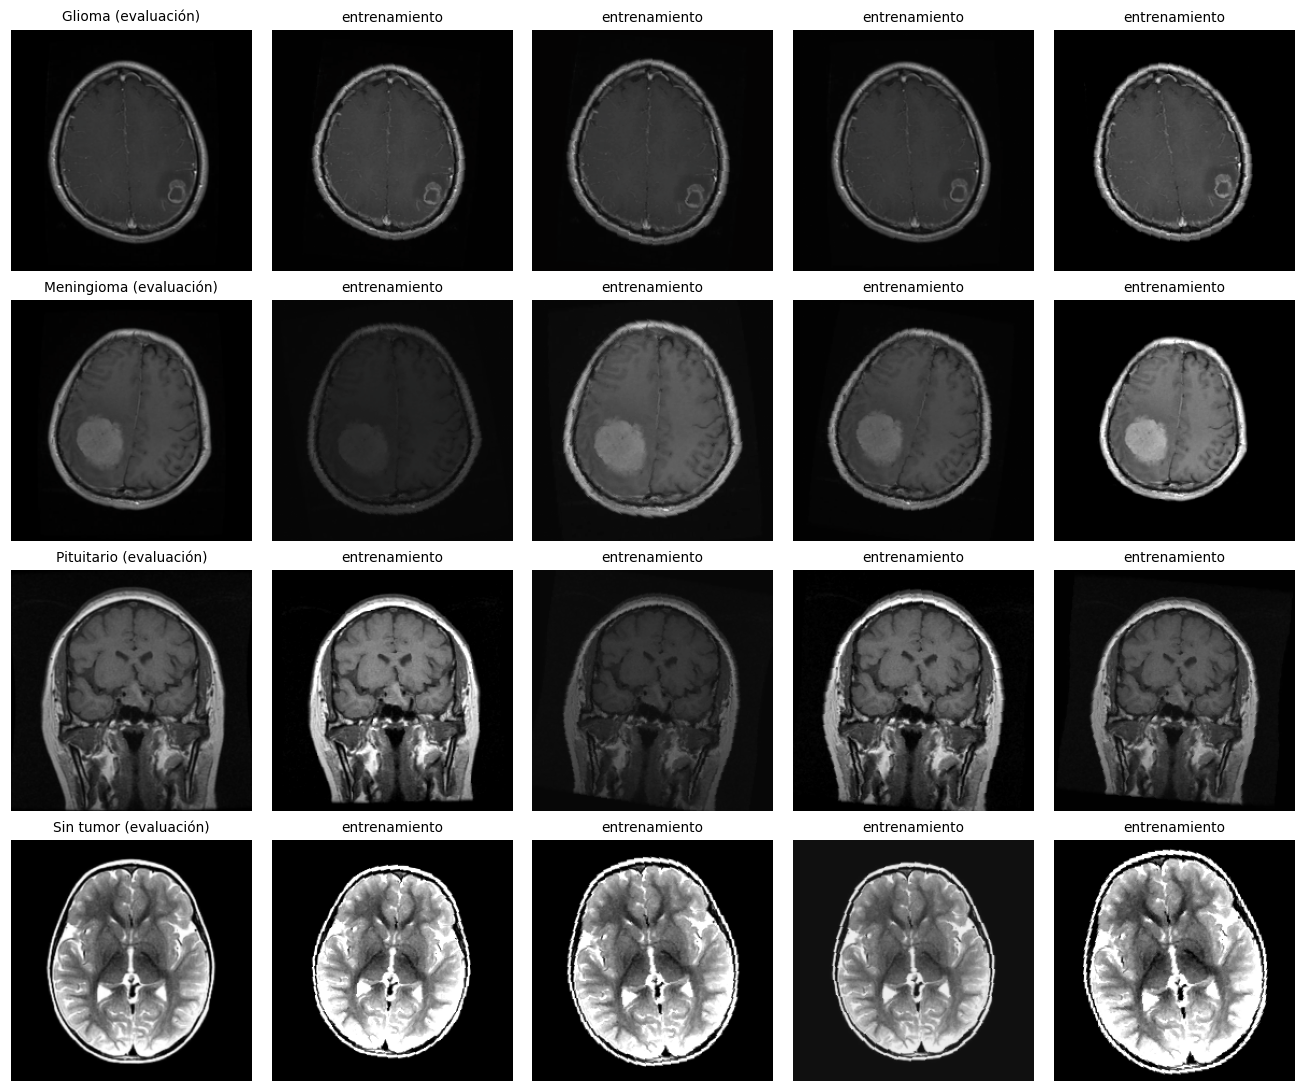

In [4]:
torch.manual_seed(1)
pipeline_train, pipeline_eval = get_train_augmentation_pipeline(), get_eval_pipeline()
media, desvio = torch.tensor(IMAGENET_MEAN)[:, None, None], torch.tensor(IMAGENET_STD)[:, None, None]


def a_imagen(tensor):
    """Deshace la normalización y pasa de (C, H, W) a (H, W, C) para matplotlib."""
    return (tensor * desvio + media).clamp(0, 1).permute(1, 2, 0).numpy()


fig, ax = plt.subplots(4, 5, figsize=(12, 10))
for fila, clase in enumerate(CLASES):
    path = df[df["clase"] == clase].sample(1, random_state=3)["path"].iloc[0]
    imagen = Image.open(path).convert("RGB")
    ax[fila, 0].imshow(a_imagen(pipeline_eval(imagen)))
    ax[fila, 0].set_title(f"{eda.ETIQUETAS[clase]} (evaluación)", fontsize=9)
    for col in range(1, 5):
        ax[fila, col].imshow(a_imagen(pipeline_train(imagen)))
        ax[fila, col].set_title("entrenamiento", fontsize=9)
for a in ax.flat:
    a.axis("off")
plt.tight_layout()
plt.show()

**Lectura.** Las variantes son razonables y el tumor sigue visible aun con el brillo al
mínimo. Dos detalles menores, aceptables porque aparecen al azar en todas las clases: en
imágenes sin fondo negro en los bordes, la rotación deja esquinas negras con borde recto;
y bajar el contraste agrisa levemente el fondo.

---
## 3. Cuantificación del atajo de brillo

El EDA mostró diferencias de brillo y contraste entre clases que coinciden con la fuente
de origen de cada una (notumor = 100% Br35H). Para medir qué tan fuerte es esa señal,
entreno una regresión logística que solo recibe **dos números por imagen: brillo medio y
desvío**. No ve ninguna forma ni textura, así que todo lo que acierte por encima del azar
(25%) lo acierta por intensidad.

Primero, las estadísticas por clase:

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score
from sklearn.model_selection import train_test_split

stats = eda.estadisticas_intensidad(df, muestra=2000)
stats.groupby("clase")[["media", "desvio", "frac_fondo"]].mean().loc[CLASES].round(1)

,media,desvio,frac_fondo
clase,,,
glioma,34.700001,38.900002,0.5
meningioma,44.299999,47.200001,0.5
pituitary,49.099998,41.200001,0.3
notumor,61.400002,61.299999,0.3


Después, el clasificador en cuatro escenarios: sin augmentation y con ColorJitter de
brillo/contraste 0.2, 0.4 y 0.6. El jitter lo simulo sobre los estadísticos, sin
reprocesar imágenes: el brillo multiplica todos los píxeles por un factor `f` (escala
media y desvío), y el contraste mezcla la imagen con su gris medio (deja la media y escala
el desvío por `c`). Como en el entrenamiento real, el jitter se aplica solo a train y se
evalúa sobre datos sin modificar.

In [6]:
X = stats[["media", "desvio"]].to_numpy()
y = stats["clase"].to_numpy()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
rng = np.random.default_rng(0)


def simular_jitter(X, b, repeticiones=10):
    muestras = []
    for _ in range(repeticiones):
        f = rng.uniform(1 - b, 1 + b, len(X))
        c = rng.uniform(1 - b, 1 + b, len(X))
        muestras.append(np.c_[X[:, 0] * f, X[:, 1] * f * c])
    return np.vstack(muestras)


def evaluar(escenario, X_train, y_train, X_test=X_te, y_test=y_te):
    pred = LogisticRegression(max_iter=2000).fit(X_train, y_train).predict(X_test)
    recalls = recall_score(y_test, pred, labels=CLASES, average=None)
    return {"escenario": escenario, "accuracy": accuracy_score(y_test, pred),
            **{f"recall {c}": r for c, r in zip(CLASES, recalls)}}


resultados = [evaluar("sin augmentation", X_tr, y_tr)]
for b in (0.2, 0.4, 0.6):
    resultados.append(evaluar(f"ColorJitter {b}", simular_jitter(X_tr, b), np.tile(y_tr, 10)))

Por último, la alternativa más fuerte: normalizar cada imagen por su propio brillo y
desvío. Así ambos quedan constantes y no informan nada; lo que sobrevive es la forma del
histograma (percentiles 1 y 99 estandarizados y fracción de fondo negro).

In [7]:
Z = np.c_[
    (stats["p1"] - stats["media"]) / stats["desvio"],
    (stats["p99"] - stats["media"]) / stats["desvio"],
    stats["frac_fondo"],
]
Z_tr, Z_te, yz_tr, yz_te = train_test_split(Z, y, test_size=0.3, stratify=y, random_state=42)
resultados.append(evaluar("normalización por imagen", Z_tr, yz_tr, Z_te, yz_te))

pd.DataFrame(resultados).set_index("escenario").round(2)

,accuracy,recall glioma,recall meningioma,recall pituitary,recall notumor
escenario,,,,,
sin augmentation,0.63,0.74,0.45,0.77,0.55
ColorJitter 0.2,0.62,0.79,0.39,0.79,0.51
ColorJitter 0.4,0.61,0.81,0.35,0.76,0.52
ColorJitter 0.6,0.60,0.81,0.33,0.75,0.53
normalización por imagen,0.56,0.63,0.33,0.80,0.49


**Lectura.**

- **Dos estadísticos de intensidad alcanzan para acertar el ~63%**, más del doble que el
  azar.
- **El ColorJitter casi no lo reduce.** Es simétrico: ensancha la distribución de cada
  clase pero no mueve su promedio. Además se aplica solo a train, y test conserva el
  sesgo intacto.
- **La normalización por imagen lo reduce más, pero no lo elimina:** la forma del
  histograma sigue delatando la fuente, mezclada con información anatómica real.

El origen está en el armado del dataset, no en el preprocesamiento. Mantengo el
ColorJitter en 0.4 por robustez a diferencias entre equipos, y mido el atajo sobre el
modelo entrenado con `evaluate.brightness_stress_test()`.

---
## 4. Secuencias de resonancia por clase

Al revisar la grilla de la sección 2 noté que la imagen de notumor tenía un aspecto
distinto al de las clases con tumor. Acá muestro 10 imágenes al azar por clase para
verificar si es un patrón.

**Para revisión médica:** lo que observo a simple vista es que glioma, meningioma y
pituitario son casi todas compatibles con **T1 con contraste** (líquido cefalorraquídeo
oscuro, lesión realzada), mientras que notumor mezcla T1 con imágenes compatibles con
**T2** (líquido brillante) y **FLAIR**. No soy especialista en imágenes: esta
identificación necesita confirmación de un profesional médico.

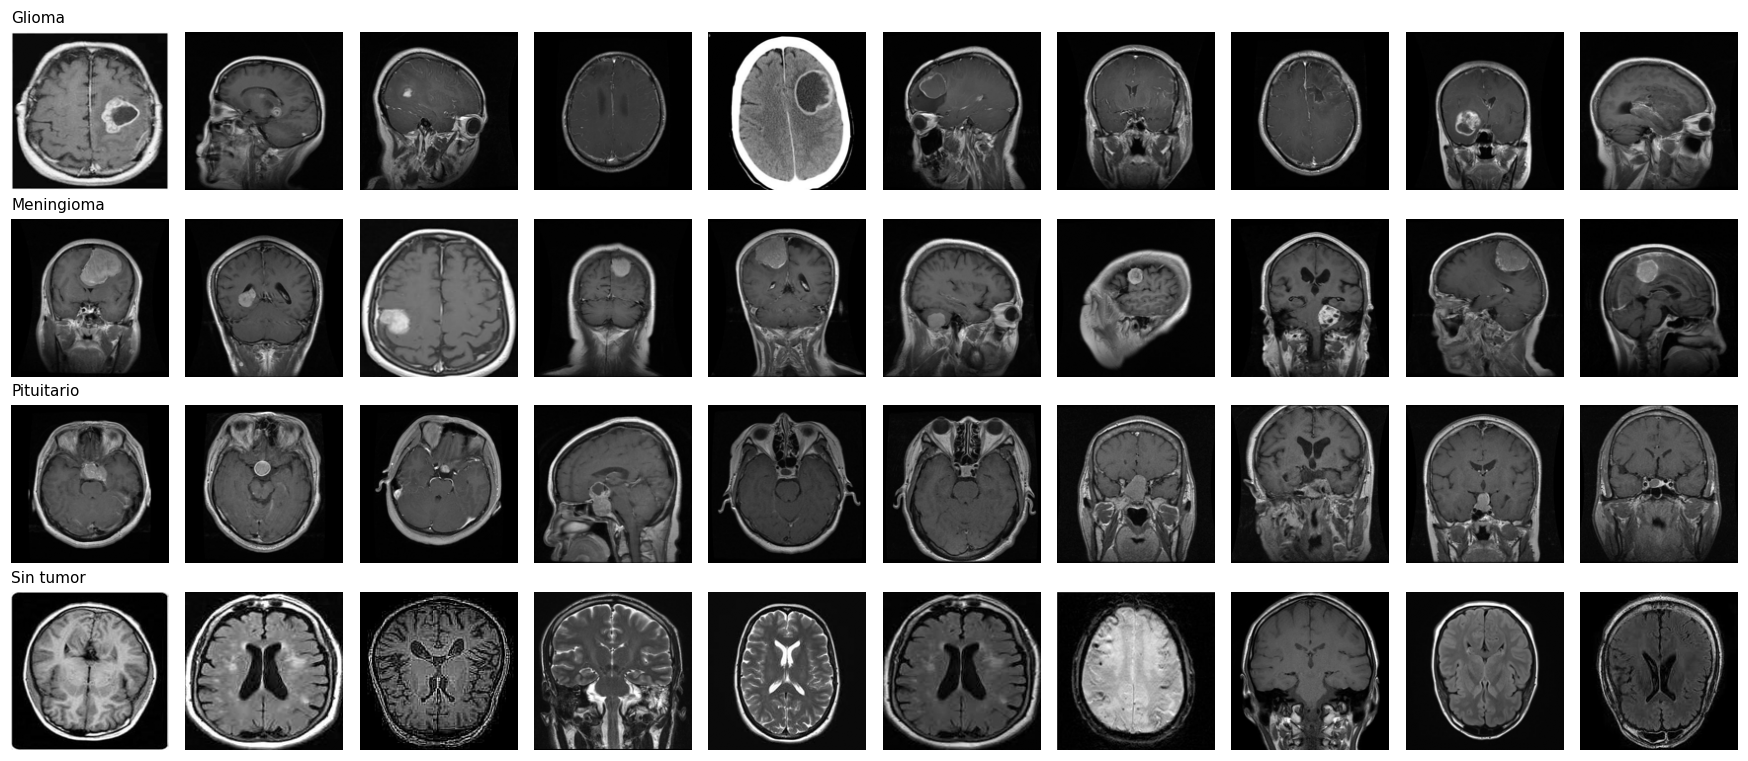

In [8]:
fig, ax = plt.subplots(4, 10, figsize=(16, 7))
for fila, clase in enumerate(CLASES):
    paths = df[df["clase"] == clase].sample(10, random_state=7)["path"]
    for col, path in enumerate(paths):
        ax[fila, col].imshow(Image.open(path).convert("L").resize((160, 160)), cmap="gray")
        ax[fila, col].axis("off")
    ax[fila, 0].set_title(eda.ETIQUETAS[clase], fontsize=10, loc="left")
plt.tight_layout()
plt.show()

**Lectura.** Si se confirma, la secuencia queda confundida con la clase. Es más grave
que la diferencia de brillo por dos motivos: ningún augmentation de intensidad convierte
una T1 en una T2 (cambia el contraste *relativo* entre tejidos), y el atajo empuja hacia
el error clínicamente costoso: ante una T2 con tumor, el modelo podría responder "sin
tumor".

**Decisiones:** acoto el uso previsto del modelo a T1 con contraste (`docs/model_card.md`),
y en la evaluación voy a etiquetar a mano, con participación médica, una muestra de
imágenes notumor de test por secuencia, para comparar el recall del modelo en cada grupo.